# Лабораторная работа №1. Метод k ближайших соседей

**Цель работы:** исследуем KNN для классификации и регрессии, проверим гипотезы улучшения и сравним библиотечный алгоритм с собственной реализацией.

Рассмотрим две задачи:

- **Классификация:** по демографическим и личностным характеристикам определим, сообщал ли респондент об употреблении каннабиса за последние 12 месяцев.
- **Регрессия:** по истории обращений оценим число новых сообщений 311 о граффити в районе Чикаго на следующую неделю. Такой прогноз позволяет оценить будущую нагрузку на городскую службу.

Для каждой задачи получим четыре результата: библиотечный бейзлайн, выбранный по валидации вариант, собственный KNN с исходными настройками и собственный KNN с теми же улучшениями. Параметры выберем до оценки на тестовой выборке.

## 1. Загрузка и проверка данных

Загрузим [Drug Consumption (UCI)](https://archive.ics.uci.edu/dataset/373/drug-consumption-quantified) и [Chicago Graffiti Removal Historical](https://data.cityofchicago.org/Service-Requests/311-Service-Requests-Graffiti-Removal-Historical/hec5-y4x5) по прямым ссылкам. Если файлы уже находятся в `datasets/`, используем их повторно.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_DIR = Path("datasets")
DATA_DIR.mkdir(exist_ok=True)
DRUG_PATH = DATA_DIR / "drug_consumption.data"
GRAFFITI_PATH = DATA_DIR / "Chicago_graffiti.csv"

def download(url, destination, min_bytes):
    if destination.exists() and destination.stat().st_size >= min_bytes:
        print(f"Уже есть: {destination} ({destination.stat().st_size / 1e6:.1f} МБ)")
        return
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urlopen(url, timeout=120) as response, temporary.open("wb") as output:
        shutil.copyfileobj(response, output)
    if temporary.stat().st_size < min_bytes:
        temporary.unlink()
        raise RuntimeError(f"Файл {destination.name} слишком мал: возможно, скачана лишь часть данных")
    temporary.replace(destination)

if not DRUG_PATH.exists():
    archive = DATA_DIR / "drug_consumption.zip"
    download("https://archive.ics.uci.edu/static/public/373/drug+consumption+quantified.zip", archive, 100_000)
    with ZipFile(archive) as zf:
        member = next(name for name in zf.namelist() if name.endswith("drug_consumption.data"))
        with zf.open(member) as source, DRUG_PATH.open("wb") as target:
            shutil.copyfileobj(source, target)
download("https://data.cityofchicago.org/api/v3/views/hec5-y4x5/export.csv?accessType=DOWNLOAD", GRAFFITI_PATH, 100_000_000)
assert DRUG_PATH.stat().st_size > 100_000
assert GRAFFITI_PATH.stat().st_size > 100_000_000


Уже есть: datasets\Chicago_graffiti.csv (268.2 МБ)


Загрузка завершена. Дальше проверим содержимое таблиц.

## 2. Классификация ответа об употреблении каннабиса

### 2.1. Целевая переменная и признаки

Прочитаем таблицу без заголовка и зададим названия столбцов по описанию UCI. Положительный класс объединим из `CL3`–`CL6`: употребление за последний год, месяц, неделю или день. В отрицательный класс войдут `CL0`–`CL2`: никогда, более десяти лет назад или более года назад.

Используем 12 входных характеристик: возраст, пол, образование, страну, этническую принадлежность, пять личностных шкал, импульсивность и поиск ощущений. Значения уже численно преобразованы авторами набора. ID и ответы о других веществах исключим.

Задача отражает связь признаков с ответом в анкете. Проверим размер таблицы, доли классов и диапазоны признаков.

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

columns = ["id", "age", "gender", "education", "country", "ethnicity", "nscore", "escore", "oscore", "ascore", "cscore", "impulsive", "ss", "alcohol", "amphet", "amyl", "benzos", "caff", "cannabis", "choc", "coke", "crack", "ecstasy", "heroin", "ketamine", "legalh", "lsd", "meth", "mushrooms", "nicotine", "semer", "vsa"]
drug = pd.read_csv(DRUG_PATH, header=None, names=columns, skipinitialspace=True)
feature_columns = columns[1:13]
X_cls = drug[feature_columns].astype(float)
y_cls = drug["cannabis"].isin(["CL3", "CL4", "CL5", "CL6"]).astype(int)
assert len(drug) == 1885 and y_cls.sum() == 999
print("Размер:", X_cls.shape, "Доли классов:", y_cls.value_counts(normalize=True).round(3).to_dict())
display(X_cls.describe().round(2))


,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,impulsive,ss
count,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00,1885.00
mean,0.03,-0.00,-0.00,0.36,-0.31,0.00,-0.00,-0.00,-0.00,-0.00,0.01,-0.00
std,0.88,0.48,0.95,0.70,0.17,1.00,1.00,1.00,1.00,1.00,0.95,0.96
min,-0.95,-0.48,-2.44,-0.57,-1.11,-3.46,-3.27,-3.27,-3.46,-3.46,-2.56,-2.08
25%,-0.95,-0.48,-0.61,-0.57,-0.32,-0.68,-0.70,-0.72,-0.61,-0.65,-0.71,-0.53
50%,-0.08,-0.48,-0.06,0.96,-0.32,0.04,0.00,-0.02,-0.02,-0.01,-0.22,0.08
75%,0.50,0.48,0.45,0.96,-0.32,0.63,0.64,0.72,0.76,0.58,0.53,0.77
max,2.59,0.48,1.98,0.96,1.91,3.27,3.27,2.90,3.46,3.46,2.90,1.92


Размер: (1885, 12) Доли классов: {1: 0.53, 0: 0.47}


Получили 1885 наблюдений и 12 входных признаков. Доли классов составляют 53% и 47%. Личностные шкалы имеют стандартное отклонение около единицы, но разброс демографических признаков отличается. Поэтому дополнительное масштабирование проверим экспериментально.

### 2.2. Разделение данных и кросс-валидация

Отложим прежние 20% наблюдений для теста с `random_state=42`. На оставшихся 80% построим три фиксированных стратифицированных фолда: каждый раз обучим модель на двух частях и проверим на третьей. Все варианты сравним на одних и тех же фолдах.

Основная метрика — F1 положительного класса, дополнительно оценим balanced accuracy. Будем показывать среднее и стандартное отклонение по трём фолдам. Это разброс оценок между частями данных, а не доверительный интервал. Масштабирование в каждом фолде обучим только на его обучающей части.

Для ориентира оценим прогноз наиболее частого класса, затем исходный KNN с пятью соседями и одинаковыми весами.

In [3]:
X_dev_c, X_test_c, y_dev_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=RANDOM_STATE)
classification_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cls_folds = list(classification_cv.split(X_dev_c, y_dev_c))

def classification_scores(y_true, y_pred):
    return {"F1": f1_score(y_true, y_pred), "Balanced accuracy": balanced_accuracy_score(y_true, y_pred)}

def summarize_cv(scores):
    return {f"{name}_{stat}": float(getattr(scores[name], stat)())
            for name in scores.columns if name != "fold" for stat in ["mean", "std"]}

class ClassificationFeatures:
    def __init__(self, representation="numeric", scaled=False):
        self.representation, self.scaled = representation, scaled

    def fit(self, frame):
        if self.representation == "personality":
            self.numeric_ = ["nscore", "escore", "oscore", "ascore", "cscore", "impulsive", "ss"]
            self.categories_ = {}
        elif self.representation == "categorical":
            categorical = ["gender", "country", "ethnicity"]
            self.numeric_ = [name for name in feature_columns if name not in categorical]
            self.categories_ = {name: np.sort(frame[name].unique()) for name in categorical}
        else:
            self.numeric_, self.categories_ = list(feature_columns), {}
        values = frame[self.numeric_].to_numpy(dtype=float)
        self.scaler_ = StandardScaler().fit(values) if self.scaled else None
        return self

    def transform(self, frame):
        numeric = frame[self.numeric_].to_numpy(dtype=float)
        if self.scaler_ is not None:
            numeric = self.scaler_.transform(numeric)
        parts = [numeric]
        for name, categories in self.categories_.items():
            parts.append((frame[name].to_numpy()[:, None] == categories[None, :]).astype(float))
        return np.column_stack(parts)

# Все варианты предобработки обучаем независимо в каждом фолде.
cls_fold_arrays = {}
for representation, scaled in [("numeric", False), ("numeric", True),
                               ("categorical", True), ("personality", True)]:
    prepared = []
    for tr, va in cls_folds:
        prep = ClassificationFeatures(representation, scaled).fit(X_dev_c.iloc[tr])
        prepared.append((prep.transform(X_dev_c.iloc[tr]), prep.transform(X_dev_c.iloc[va]),
                         y_dev_c.iloc[tr].to_numpy(), y_dev_c.iloc[va].to_numpy()))
    cls_fold_arrays[(representation, scaled)] = prepared

def evaluate_cls_cv(k=5, weights="uniform", scaled=False, implementation="sklearn", representation="numeric", p=2, threshold=0.5):
    scores = []
    for fold, (a, b, ytr, yva) in enumerate(cls_fold_arrays[(representation, scaled)], 1):
        model = (KNeighborsClassifier(n_neighbors=k, weights=weights, p=p) if implementation == "sklearn"
                 else MyKNN(k=k, weights=weights, p=p))
        model.fit(a, ytr)
        scores.append({"fold": fold, **classification_scores(yva, (model.predict_proba(b)[:, 1] > threshold).astype(int))})
    return pd.DataFrame(scores)

majority_scores = pd.DataFrame([
    {"fold": fold, **classification_scores(yva, np.full(len(yva), np.bincount(ytr).argmax()))}
    for fold, (_, _, ytr, yva) in enumerate(cls_fold_arrays[("numeric", False)], 1)])
base_cls_cv = evaluate_cls_cv()
display(pd.DataFrame([
    {"Модель": "Большинство", **summarize_cv(majority_scores)},
    {"Модель": "KNN, k=5", **summarize_cv(base_cls_cv)},
]).round(3))

,Модель,F1_mean,F1_std,Balanced accuracy_mean,Balanced accuracy_std
0,Большинство,0.693,0.001,0.500,0.000
1,"KNN, k=5",0.798,0.013,0.788,0.012


Средний F1 исходного KNN на CV составляет около 0.798. Прогноз большинства даёт около 0.693 при balanced accuracy 0.500. Сохраним исходный KNN с пятью соседями и евклидовым расстоянием как точку отсчёта.

### 2.3. Гипотезы о признаках и расстоянии

Для KNN важно, какие объекты считаются близкими. Проверим несколько содержательных изменений:

- Манхэттенское расстояние складывает абсолютные разности и может иначе учитывать отдельные сильные отличия, чем евклидово.
- One-hot для пола, страны и этнической принадлежности убирает искусственное числовое расстояние между категориями. Числовые шкалы стандартизируем, фиктивные признаки оставим нулями и единицами. Неизвестная категория получает нули, категории определяем только на обучении фолда.
- Набор только из семи личностных шкал проверит, полезна ли демография для поиска соседей или добавляет шум.

Сравним эти варианты с исходными и стандартизованными 12 признаками. Для каждого представления переберём 3, 5, 11, 21, 31 и 41 соседа, одинаковые веса и веса по расстоянию, `p=1` и `p=2`. Критерий выбора — максимальный средний F1 на прежних трёх фолдах. Расширение поиска не гарантирует улучшения на тесте; тест не участвует в выборе.

После выбора представления и соседей проверим пороги вероятности от 0.30 до 0.60 с шагом 0.05. F1 положительного класса может выигрывать от порога, отличающегося от 0.5. Порог выберем по тем же CV-фолдам; оценим также изменение balanced accuracy. Это дополнительная степень настройки на CV, а не гарантия улучшения тестового результата.

In [4]:
rows = []
for representation, scaled in cls_fold_arrays:
    for p in [1, 2]:
        for k in [3, 5, 11, 21, 31, 41]:
            for weights in ["uniform", "distance"]:
                scores = evaluate_cls_cv(k, weights, scaled, representation=representation, p=p)
                rows.append({"representation": representation, "scaled": scaled, "p": p,
                             "k": k, "weights": weights, **summarize_cv(scores),
                             "fold_scores": scores.to_dict(orient="records")})
cls_search = pd.DataFrame(rows).sort_values("F1_mean", ascending=False, kind="stable")
display(cls_search.drop(columns="fold_scores").head(12).round(4))
best_c = cls_search.iloc[0]
print("Выбрано по среднему F1:", best_c[["representation", "scaled", "p", "k", "weights"]].to_dict())

,representation,scaled,p,k,weights,F1_mean,F1_std,Balanced accuracy_mean,Balanced accuracy_std
42,numeric,True,2,21,uniform,0.8200,0.0278,0.8152,0.0253
43,numeric,True,2,21,distance,0.8194,0.0248,0.8136,0.0224
9,numeric,False,1,31,distance,0.8180,0.0139,0.8124,0.0090
57,categorical,True,1,31,distance,0.8176,0.0218,0.8169,0.0165
21,numeric,False,2,31,distance,0.8176,0.0173,0.8116,0.0118
54,categorical,True,1,21,uniform,0.8171,0.0250,0.8144,0.0193
35,numeric,True,1,41,distance,0.8169,0.0232,0.8154,0.0198
33,numeric,True,1,31,distance,0.8169,0.0178,0.8145,0.0134
32,numeric,True,1,31,uniform,0.8167,0.0125,0.8146,0.0076
4,numeric,False,1,11,uniform,0.8165,0.0165,0.8120,0.0122


Выбрано по среднему F1: {'representation': 'numeric', 'scaled': True, 'p': 2, 'k': 21, 'weights': 'uniform'}


Сначала сравним гипотезы при фиксированных пяти соседях и одинаковых весах: это позволит отделить влияние признаков и расстояния от подбора `k`. Затем сопоставим лучшие конфигурации каждого представления. Одинаковые фолды сохраняем во всех проверках.

In [5]:
def config_f1(representation, scaled, p):
    return float(cls_search.loc[(cls_search.representation == representation) & (cls_search.scaled == scaled)
                 & (cls_search.p == p) & (cls_search.k == 5) & (cls_search.weights == "uniform"), "F1_mean"].iloc[0])

cls_hypotheses = pd.DataFrame([
    {"Гипотеза": "Стандартизация 12 признаков", "До": config_f1("numeric", False, 2), "После": config_f1("numeric", True, 2)},
    {"Гипотеза": "Манхэттенское расстояние, стандартизованные признаки", "До": config_f1("numeric", True, 2), "После": config_f1("numeric", True, 1)},
    {"Гипотеза": "Категориальная демография, евклидово расстояние", "До": config_f1("numeric", True, 2), "После": config_f1("categorical", True, 2)},
    {"Гипотеза": "Только личностные шкалы, евклидово расстояние", "До": config_f1("numeric", True, 2), "После": config_f1("personality", True, 2)},
])
cls_hypotheses["Изменение среднего F1"] = cls_hypotheses["После"] - cls_hypotheses["До"]
display(cls_hypotheses.round(4))
display(cls_search.groupby(["representation", "scaled"], sort=False).head(1).drop(columns="fold_scores").round(4))

,Гипотеза,До,После,Изменение среднего F1
0,Стандартизация 12 признаков,0.7982,0.8002,0.0020
1,"Манхэттенское расстояние, стандартизованные признаки",0.8002,0.8057,0.0055
2,"Категориальная демография, евклидово расстояние",0.8002,0.7947,-0.0055
3,"Только личностные шкалы, евклидово расстояние",0.8002,0.7352,-0.0650


,representation,scaled,p,k,weights,F1_mean,F1_std,Balanced accuracy_mean,Balanced accuracy_std
42,numeric,True,2,21,uniform,0.8200,0.0278,0.8152,0.0253
9,numeric,False,1,31,distance,0.8180,0.0139,0.8124,0.0090
57,categorical,True,1,31,distance,0.8176,0.0218,0.8169,0.0165
82,personality,True,1,41,uniform,0.7769,0.0134,0.7521,0.0101


### 2.4. Порог положительного ответа

Для выбранных признаков, расстояния и соседей оценим несколько порогов вероятности на тех же трёх фолдах. Меняется только правило получения класса: положительный ответ выдаём, если вероятность строго больше порога. Средний F1 выбирает порог, balanced accuracy покажет сопутствующее изменение распознавания двух классов. После этого зафиксируем все настройки до финальной оценки.

In [6]:
threshold_rows = []
for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    scores = evaluate_cls_cv(int(best_c.k), str(best_c.weights), bool(best_c.scaled),
                            representation=str(best_c.representation), p=int(best_c.p), threshold=threshold)
    threshold_rows.append({"threshold": threshold, **summarize_cv(scores),
                           "fold_scores": scores.to_dict(orient="records")})
threshold_search = pd.DataFrame(threshold_rows).sort_values("F1_mean", ascending=False, kind="stable")
display(threshold_search.drop(columns="fold_scores").round(4))
best_c = best_c.copy()
for name, value in threshold_search.iloc[0].items():
    best_c[name] = value
print("Выбранный порог:", best_c.threshold)

class ThresholdClassifier:
    def __init__(self, model, threshold=0.5):
        self.model, self.threshold = model, threshold

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict(self, X):
        return (self.model.predict_proba(X)[:, 1] > self.threshold).astype(int)

,threshold,F1_mean,F1_std,Balanced accuracy_mean,Balanced accuracy_std
4,0.50,0.8200,0.0278,0.8152,0.0253
1,0.35,0.8173,0.0134,0.7879,0.0171
2,0.40,0.8164,0.0221,0.7952,0.0219
3,0.45,0.8161,0.0166,0.8034,0.0173
0,0.30,0.8132,0.0152,0.7737,0.0224
5,0.55,0.8006,0.0240,0.8040,0.0220
6,0.60,0.7798,0.0223,0.7919,0.0187


Выбранный порог: 0.5


Лучшее среднее CV получено для представления «все числовые признаки»: число соседей 21, p=2, веса `uniform`. Средний F1 равен 0.8200, стандартное отклонение — 0.0278. У исходного KNN средний F1 составляет 0.7982.

После выбора соседей по CV выбран порог 0.50. При исходном пороге 0.5 средний F1 этой конфигурации равен 0.8200, при выбранном — 0.8200. Balanced accuracy при выбранном пороге на CV равна 0.8152. Уменьшение порога увеличивает число положительных ответов; оба вида ошибок нужно рассматривать вместе с F1.

Гипотеза «Стандартизация 12 признаков» подтвердилась по среднему F1 этих фолдов: 0.7982 и 0.8002. Это сравнение при пяти соседях; общий выбор настроек показан отдельно в таблице поиска.

Гипотеза «Манхэттенское расстояние, стандартизованные признаки» подтвердилась по среднему F1 этих фолдов: 0.8002 и 0.8057. Это сравнение при пяти соседях; общий выбор настроек показан отдельно в таблице поиска.

Гипотеза «Категориальная демография, евклидово расстояние» не подтвердилась по среднему F1 этих фолдов: 0.8002 и 0.7947. Это сравнение при пяти соседях; общий выбор настроек показан отдельно в таблице поиска.

Гипотеза «Только личностные шкалы, евклидово расстояние» не подтвердилась по среднему F1 этих фолдов: 0.8002 и 0.7352. Это сравнение при пяти соседях; общий выбор настроек показан отдельно в таблице поиска.

## 3. Прогноз числа обращений о граффити

### 3.1. Подготовка недельной таблицы

В исходном файле каждая строка описывает обращение. Для прогноза нагрузки построим другую таблицу: одна строка будет соответствовать **району и прогнозируемой неделе**. Целевое значение `y` — число новых обращений за эту неделю.

Удалим повторяющиеся номера обращений, строки с пометкой `Dup`, некорректные даты и неизвестные районы. Считать обращения будем по `Creation Date`; дата завершения работы службы не является датой поступления сообщения. Создадим календарь для всех 77 Community Area и заполним отсутствующие сочетания района и недели нулями.

Затем рассчитаем признаки внутри каждого района:

| Признак | Смысл |
| --- | --- |
| `lag_1` | Обращения за предыдущую завершённую неделю |
| `mean_3` | Среднее за три предыдущие недели |
| `sum_4` | Сумма за четыре предыдущие недели |
| `lag_52` | Обращения 52 недели назад — приближение к аналогичной неделе прошлого года |
| `week_sin`, `week_cos` | Циклическое представление номера прогнозируемой недели |

Используем `shift(1)` перед скользящими агрегатами, чтобы целевая неделя не попадала в собственные признаки. Номер будущей недели известен в момент прогноза.

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

graffiti = pd.read_csv(GRAFFITI_PATH, usecols=["Creation Date", "Status", "Service Request Number", "Community Area"], low_memory=False)
assert len(graffiti) > 1_000_000, "Похоже, API вернул неполный файл"
graffiti["date"] = pd.to_datetime(graffiti["Creation Date"], format="%m/%d/%Y", errors="coerce")
graffiti["area"] = pd.to_numeric(graffiti["Community Area"], errors="coerce")
graffiti = graffiti.drop_duplicates("Service Request Number")
graffiti = graffiti[graffiti["date"].between("2011-01-01", "2018-12-02") & graffiti["area"].between(1, 77) & ~graffiti["Status"].str.contains("Dup", na=False)].copy()
graffiti["area"] = graffiti["area"].astype(int)
graffiti["week"] = graffiti["date"].dt.to_period("W-SUN").dt.start_time
weekly = graffiti.groupby(["area", "week"]).size().rename("y")
calendar = pd.MultiIndex.from_product([range(1, 78), pd.date_range("2011-01-03", "2018-11-26", freq="W-MON")], names=["area", "week"])
weekly = weekly.reindex(calendar, fill_value=0).reset_index()
weekly = weekly.sort_values(["area", "week"]).reset_index(drop=True)
g = weekly.groupby("area")["y"]
weekly["lag_1"] = g.shift(1)
weekly["mean_3"] = g.transform(lambda s: s.shift(1).rolling(3).mean())
weekly["sum_4"] = g.transform(lambda s: s.shift(1).rolling(4).sum())
weekly["lag_52"] = g.shift(52)
weekly["week_sin"] = np.sin(2 * np.pi * weekly["week"].dt.isocalendar().week.astype(int) / 52.18)
weekly["week_cos"] = np.cos(2 * np.pi * weekly["week"].dt.isocalendar().week.astype(int) / 52.18)
weekly = weekly.dropna().reset_index(drop=True)
print("Обращений после фильтрации:", len(graffiti), "Строк модели:", len(weekly), "Районов:", weekly.area.nunique())
display(weekly.head())


,area,week,y,lag_1,mean_3,sum_4,lag_52,week_sin,week_cos
0,1,2012-01-02,26,35.0,38.333333,152.0,38.0,0.120123,0.992759
1,1,2012-01-09,19,26.0,33.333333,141.0,45.0,0.238506,0.971141
2,1,2012-01-16,23,19.0,26.666667,119.0,31.0,0.353435,0.935459
3,1,2012-01-23,34,23.0,22.666667,103.0,39.0,0.463246,0.886230
4,1,2012-01-30,41,34.0,25.333333,102.0,34.0,0.566348,0.824166


Обращений после фильтрации: 956880 Строк модели: 27797 Районов: 77


Получили **27 797 районных недель** после подготовки годовой истории. Из-за `lag_52` модельная таблица начинается в январе 2012 года; строки одинаковы для всех вариантов модели.

### 3.2. Временная кросс-валидация

Данные до конца 2017 года используем для разработки, недели с началом в январе–ноябре 2018 года оставим для теста. Последняя тестовая неделя заканчивается 2 декабря. Построим три годовых фолда с расширяющимся обучающим периодом:

| Фолд | Обучение | Проверка |
| --- | --- | --- |
| 1 | 2012–2014 | 2015 |
| 2 | 2012–2015 | 2016 |
| 3 | 2012–2016 | 2017 |

Все районы одной недели попадают в одну часть. Перемешивать районные недели нельзя: обучение должно предшествовать проверке. В каждом фолде стандартизацию обучим заново только на прошлом периоде.

Проверяем прогноз на одну неделю вперёд. При переходе к следующей неделе доступны фактические счётчики уже завершённых недель, в том числе внутри проверочного года. Модель в течение года не переобучаем. Основная метрика — MAE в обращениях на район за неделю, дополнительная — RMSE. Выбирать настройки будем по среднему MAE трёх годов.

In [8]:
dev_r = weekly[weekly.week < "2018-01-01"].copy()
test_r = weekly[(weekly.week >= "2018-01-01") & (weekly.week < "2018-12-01")].copy()
base_cols = ["area", "lag_1", "mean_3", "sum_4"]
improved_cols = ["lag_1", "mean_3", "sum_4", "lag_52", "week_sin", "week_cos"]
all_areas = list(range(1, 78))
reg_folds = []
for year in [2015, 2016, 2017]:
    start, end = pd.Timestamp(year, 1, 1), pd.Timestamp(year + 1, 1, 1)
    tr = np.flatnonzero((dev_r.week < start).to_numpy())
    va = np.flatnonzero(((dev_r.week >= start) & (dev_r.week < end)).to_numpy())
    assert dev_r.iloc[tr].week.max() + pd.Timedelta(weeks=1) <= dev_r.iloc[va].week.min()
    assert set(tr).isdisjoint(va)
    reg_folds.append((tr, va))
assert dev_r.week.max() < test_r.week.min()

def regression_features(frame, areas, scaler=None, fit=False):
    numeric = frame[improved_cols].to_numpy(dtype=float)
    if fit:
        scaler = StandardScaler().fit(numeric)
    numeric = scaler.transform(numeric)
    area_codes = pd.Categorical(frame.area, categories=areas).codes
    assert (area_codes >= 0).all()
    return np.column_stack([numeric, np.eye(len(areas))[area_codes]]), scaler

# Каждое преобразование обучаем отдельно внутри своего временного фолда.
reg_fold_arrays = {}
for mode in ["raw", "scaled", "one_hot", "seasonal"]:
    prepared = []
    for tr, va in reg_folds:
        train, valid = dev_r.iloc[tr], dev_r.iloc[va]
        if mode == "seasonal":
            a, scaler = regression_features(train, all_areas, fit=True)
            b, _ = regression_features(valid, all_areas, scaler)
        else:
            cols = base_cols if mode != "one_hot" else base_cols[1:]
            a, b = train[cols].to_numpy(dtype=float), valid[cols].to_numpy(dtype=float)
            if mode != "raw":
                scaler = StandardScaler().fit(a)
                a, b = scaler.transform(a), scaler.transform(b)
            if mode == "one_hot":
                a = np.column_stack([a, np.eye(77)[train.area.to_numpy() - 1]])
                b = np.column_stack([b, np.eye(77)[valid.area.to_numpy() - 1]])
        prepared.append((a, b, train.y.to_numpy(), valid.y.to_numpy()))
    reg_fold_arrays[mode] = prepared

def regression_scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

def evaluate_reg_cv(k=5, weights="uniform", mode="raw", implementation="sklearn"):
    scores = []
    for fold, (a, b, ytr, yva) in enumerate(reg_fold_arrays[mode], 1):
        model = (KNeighborsRegressor(n_neighbors=k, weights=weights) if implementation == "sklearn"
                 else MyKNN(k=k, weights=weights, task="regression"))
        model.fit(a, ytr)
        scores.append({"fold": fold, **regression_scores(yva, model.predict(b))})
    return pd.DataFrame(scores)

base_reg_cv = evaluate_reg_cv()
naive_reg_cv = pd.DataFrame([
    {"fold": fold, **regression_scores(dev_r.iloc[va].y, dev_r.iloc[va].lag_1)}
    for fold, (_, va) in enumerate(reg_folds, 1)])
display(pd.DataFrame([
    {"Модель": "Прошлая неделя", **summarize_cv(naive_reg_cv)},
    {"Модель": "KNN, k=5", **summarize_cv(base_reg_cv)},
]).round(3))
display(pd.DataFrame([
    {"Фолд": i, "Обучение, строк": len(tr), "Проверка, строк": len(va),
     "Год проверки": int(dev_r.iloc[va].week.dt.year.iloc[0])}
    for i, (tr, va) in enumerate(reg_folds, 1)]))

,Модель,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,Прошлая неделя,12.763,0.452,23.855,0.935
1,"KNN, k=5",11.885,0.550,21.687,0.740


,Фолд,"Обучение, строк","Проверка, строк",Год проверки
0,1,12089,4004,2015
1,2,16093,4004,2016
2,3,20097,4004,2017


Исходный KNN получил среднюю MAE 11.89 со стандартным отклонением 0.55. Прогноз по прошлой неделе дал среднюю MAE 12.76. Усредняем годовые оценки с одинаковым весом каждого фолда.

### 3.3. Недельная динамика

Построим число обращений по городу для начального обучающего периода, до первого проверочного года. По графику рассмотрим динамику, затем проверим пользу сезонных признаков на временной CV.

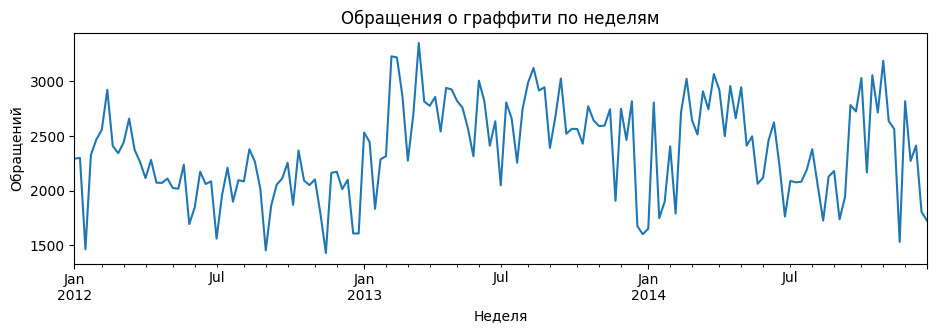

In [9]:
city_weekly = dev_r.iloc[reg_folds[0][0]].groupby("week")["y"].sum()
ax = city_weekly.plot(figsize=(11, 3), title="Обращения о граффити по неделям")
ax.set(xlabel="Неделя", ylabel="Обращений")
plt.show()


Городская сумма помогает увидеть изменения нагрузки, но скрывает различия районов. Поэтому пользу признаков будем оценивать по ошибкам районных прогнозов.

### 3.4. Гипотезы о подготовке признаков

При пяти соседях и одинаковых весах последовательно проверим стандартизацию, one-hot района и добавление сезонности с прошлогодним счётчиком. Сравним средние MAE и RMSE на трёх временных фолдах. Эффект каждого шага относится к этой последовательности и выбранным параметрам KNN.

In [10]:
reg_steps = [("Исходные признаки", "raw"), ("Стандартизация", "scaled"),
             ("Стандартизация и one-hot", "one_hot"), ("Стандартизация, one-hot и сезонность", "seasonal")]
reg_hypotheses = pd.DataFrame([
    {"Вариант": name, "mode": mode, **summarize_cv(scores), "fold_scores": scores.to_dict(orient="records")}
    for name, mode in reg_steps for scores in [evaluate_reg_cv(mode=mode)]])
reg_hypotheses["Изменение среднего MAE"] = reg_hypotheses.MAE_mean.diff().fillna(0)
display(reg_hypotheses.drop(columns=["mode", "fold_scores"]).round(3))

,Вариант,MAE_mean,MAE_std,RMSE_mean,RMSE_std,Изменение среднего MAE
0,Исходные признаки,11.885,0.550,21.687,0.740,0.000
1,Стандартизация,11.645,0.296,21.292,0.673,-0.241
2,Стандартизация и one-hot,11.629,0.244,21.123,1.005,-0.016
3,"Стандартизация, one-hot и сезонность",11.867,0.294,21.421,0.857,0.238


Результаты последовательных изменений приведены в таблице: отрицательное изменение среднего MAE означает уменьшение ошибки. Вывод по каждому шагу относится к трём проверочным годам, при пяти соседях и остальных условиях этой последовательности.

Гипотеза «Стандартизация» подтвердилась в этой последовательности: средний MAE = 11.64.

Гипотеза «Стандартизация и one-hot» подтвердилась в этой последовательности: средний MAE = 11.63.

Гипотеза «Стандартизация, one-hot и сезонность» не подтвердилась в этой последовательности: средний MAE = 11.87.

### 3.5. Число соседей и веса

На признаках со стандартизацией, one-hot и сезонностью сравним 5, 15 и 31 соседа и два способа взвешивания. Более широкая группа соседей может уменьшить шум счётчиков. Все параметры сравним на тех же временных фолдах, выберем вариант по минимальному среднему MAE.

In [11]:
rows = []
for k in [5, 15, 31]:
    for weights in ["uniform", "distance"]:
        scores = evaluate_reg_cv(k, weights, mode="seasonal")
        rows.append({"k": k, "weights": weights, **summarize_cv(scores),
                     "fold_scores": scores.to_dict(orient="records")})
reg_search = pd.DataFrame(rows).sort_values("MAE_mean", kind="stable")
display(reg_search.drop(columns="fold_scores").round(3))
best_r = reg_search.iloc[0]
print("Выбрано по среднему MAE:", best_r[["k", "weights"]].to_dict())

,k,weights,MAE_mean,MAE_std,RMSE_mean,RMSE_std
4,31,uniform,10.968,0.244,19.875,0.885
5,31,distance,10.976,0.254,19.908,0.878
2,15,uniform,11.167,0.295,20.250,0.934
3,15,distance,11.206,0.291,20.315,0.911
0,5,uniform,11.867,0.294,21.421,0.857
1,5,distance,11.964,0.280,21.611,0.833


Выбрано по среднему MAE: {'k': 31, 'weights': 'uniform'}


Минимальный средний MAE равен 10.97, стандартное отклонение — 0.24. Выбрано число соседей 31 и одинаковые веса (`uniform`). Исходный KNN на тех же фолдах дал 11.89. Зафиксируем выбранные параметры для обеих реализаций.

## 4. Собственная реализация KNN

Реализуем обе задачи в одном классе на NumPy. На этапе `fit` сохраним обучающие признаки и ответы. При прогнозе вычислим евклидовы или манхэттенские расстояния и выберем `k` ближайших объектов через `argpartition`.

Для классификации сложим голоса соседей и выберем класс с наибольшим весом. Для регрессии рассчитаем взвешенное среднее. В режиме `distance` используем веса `1/d`; при точных совпадениях учтём только их. При равных голосах выберем первый класс в отсортированном списке.

Расстояния рассчитаем пакетами по 128 запросов: это ограничит расход памяти. Поиск соседей выполним самостоятельно, без готового алгоритма sklearn. При одинаковых расстояниях на границе выбранной группы набор соседей может отличаться от библиотечного.

In [12]:
class MyKNN:
    def __init__(self, k=5, weights="uniform", task="classification", batch_size=128, p=2):
        self.k, self.weights, self.task, self.batch_size = k, weights, task, batch_size
        self.p = p

    def fit(self, X, y):
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y)
        if not 1 <= self.k <= len(self.X):
            raise ValueError("k должно быть между 1 и числом обучающих объектов")
        return self

    def _predict(self, X, probabilities=False):
        X = np.asarray(X, dtype=float)
        predictions = []
        train_norm = np.sum(self.X ** 2, axis=1)
        for start in range(0, len(X), self.batch_size):
            batch = X[start:start + self.batch_size]
            if self.p == 2:
                distances_all = np.sqrt(np.maximum(np.sum(batch ** 2, axis=1)[:, None]
                    + train_norm[None, :] - 2 * batch @ self.X.T, 0))
            elif self.p == 1:
                distances_all = np.zeros((len(batch), len(self.X)))
                for feature in range(self.X.shape[1]):
                    distances_all += np.abs(batch[:, feature, None] - self.X[None, :, feature])
            else:
                raise ValueError("Поддерживаются p=1 и p=2")
            near = np.argpartition(distances_all, self.k - 1, axis=1)[:, :self.k]
            distances = np.take_along_axis(distances_all, near, axis=1)
            targets = self.y[near]
            if self.weights == "uniform":
                w = np.ones_like(distances)
            elif self.weights == "distance":
                w = 1 / np.maximum(distances, 1e-12)
                zeros = distances < 1e-12
                w = np.where(zeros.any(axis=1, keepdims=True), zeros.astype(float), w)
            else:
                raise ValueError("Неизвестный тип весов")
            if self.task == "regression":
                out = (w * targets).sum(axis=1) / w.sum(axis=1)
            elif self.task == "classification":
                classes = np.unique(self.y)
                votes = np.stack([(w * (targets == c)).sum(axis=1) for c in classes], axis=1)
                out = votes / votes.sum(axis=1, keepdims=True) if probabilities else classes[np.argmax(votes, axis=1)]
            else:
                raise ValueError("Неизвестная задача")
            predictions.extend(out)
        return np.asarray(predictions)


    def predict(self, X):
        return self._predict(X)

    def predict_proba(self, X):
        if self.task != "classification":
            raise ValueError("Вероятности доступны только для классификации")
        return self._predict(X, probabilities=True)


### 4.1. Проверка вычислений

Сравним обе метрики расстояния и два вида весов со sklearn на искусственных данных без граничных равных расстояний. Отдельно проверим, что точные совпадения имеют приоритет при взвешивании по расстоянию. Качество на выбранных задачах оценим на CV и тесте.

In [13]:
rng = np.random.default_rng(42)
check_x, check_test = rng.normal(size=(150, 6)), rng.normal(size=(30, 6))
check_y = rng.integers(0, 2, 150)
check_targets = rng.normal(size=150)
for p in [1, 2]:
    for weights in ["uniform", "distance"]:
        assert np.array_equal(MyKNN(k=5, p=p, weights=weights).fit(check_x, check_y).predict(check_test),
                              KNeighborsClassifier(n_neighbors=5, p=p, weights=weights).fit(check_x, check_y).predict(check_test))
        assert np.allclose(MyKNN(k=5, p=p, weights=weights, task="regression").fit(check_x, check_targets).predict(check_test),
                           KNeighborsRegressor(n_neighbors=5, p=p, weights=weights).fit(check_x, check_targets).predict(check_test))
# При точном совпадении в режиме distance учитываем только совпавших соседей.
exact_x, exact_y = np.array([[0.], [0.], [2.]]), np.array([1., 3., 20.])
assert np.allclose(MyKNN(k=3, weights="distance", task="regression").fit(exact_x, exact_y).predict([[0.]]), [2.])
print("Оба расстояния и вида весов проверены; точные совпадения обработаны корректно")

Оба расстояния и вида весов проверены; точные совпадения обработаны корректно


Обе проверки пройдены: на данном подмножестве собственный KNN воспроизводит библиотечные прогнозы. Перейдём к сравнению на полных отложенных наборах.

### 4.2. Сравнение реализаций на кросс-валидации

Повторим оценку исходных и выбранных вариантов собственным KNN на тех же фолдах и с той же подготовкой признаков. Так сравним вычисления алгоритмов до финальной оценки на тесте. Отдельный подбор параметров для собственной реализации не выполняем.

In [14]:
cv_rows = []
cv_record_metrics = {}
for task in ["classification", "regression"]:
    for implementation in ["sklearn", "numpy"]:
        for variant in ["baseline", "tuned"]:
            tuned = variant == "tuned"
            if task == "classification":
                scores = evaluate_cls_cv(int(best_c.k) if tuned else 5,
                                         str(best_c.weights) if tuned else "uniform",
                                         bool(best_c.scaled) if tuned else False, implementation,
                                         representation=str(best_c.representation) if tuned else "numeric",
                                         p=int(best_c.p) if tuned else 2, threshold=float(best_c.threshold) if tuned else 0.5)
            else:
                scores = evaluate_reg_cv(int(best_r.k) if tuned else 5,
                                         str(best_r.weights) if tuned else "uniform",
                                         "seasonal" if tuned else "raw", implementation)
            summary = summarize_cv(scores)
            cv_record_metrics[(task, implementation, variant)] = {**summary, "fold_scores": scores.to_dict(orient="records")}
            cv_rows.append({"task": task, "implementation": implementation, "variant": variant, **summary})
cv_comparison = pd.DataFrame(cv_rows)
for task in ["classification", "regression"]:
    display(cv_comparison[cv_comparison.task == task].dropna(axis=1, how="all").round(3))

,task,implementation,variant,F1_mean,F1_std,Balanced accuracy_mean,Balanced accuracy_std
0,classification,sklearn,baseline,0.798,0.013,0.788,0.012
1,classification,sklearn,tuned,0.820,0.028,0.815,0.025
2,classification,numpy,baseline,0.798,0.013,0.788,0.012
3,classification,numpy,tuned,0.820,0.028,0.815,0.025


,task,implementation,variant,MAE_mean,MAE_std,RMSE_mean,RMSE_std
4,regression,sklearn,baseline,11.885,0.550,21.687,0.740
5,regression,sklearn,tuned,10.968,0.244,19.875,0.885
6,regression,numpy,baseline,11.878,0.558,21.684,0.743
7,regression,numpy,tuned,10.968,0.244,19.875,0.885


Сопоставим средние метрики и их разброс в таблицах. Предобработка, строки фолдов и параметры соответствующих реализаций одинаковы. Незначительные различия возможны при равных расстояниях на границе группы соседей. Перейдём к итоговому обучению на всей части разработки.

## 5. Финальная оценка на тесте

### 5.1. Классификация

Обучим четыре заранее выбранных варианта на всех 80% данных разработки. Для настроенных моделей используем параметры и масштабирование, выбранные по среднему F1 на CV. Оценим их на общих отложенных 20%.

In [15]:
Xdev_c = X_dev_c.to_numpy(dtype=float)
Xtest_c = X_test_c.to_numpy(dtype=float)
ydev_c = y_dev_c.to_numpy()
cls_results = []
for name, model in [
    ("sklearn, базовый", KNeighborsClassifier(n_neighbors=5)),
    ("свой, базовый", MyKNN(k=5)),
]:
    model.fit(Xdev_c, ydev_c)
    cls_results.append({"Вариант": name, **classification_scores(y_test_c, model.predict(Xtest_c))})

final_cls_preparation = ClassificationFeatures(str(best_c.representation), bool(best_c.scaled)).fit(X_dev_c)
Xfit, Xeval = final_cls_preparation.transform(X_dev_c), final_cls_preparation.transform(X_test_c)
k_c, weights_c, p_c = int(best_c.k), str(best_c.weights), int(best_c.p)
for name, model in [
    ("sklearn, улучшенный", KNeighborsClassifier(n_neighbors=k_c, weights=weights_c, p=p_c)),
    ("свой, улучшенный", MyKNN(k=k_c, weights=weights_c, p=p_c)),
]:
    model = ThresholdClassifier(model, float(best_c.threshold))
    model.fit(Xfit, ydev_c)
    cls_results.append({"Вариант": name, **classification_scores(y_test_c, model.predict(Xeval))})
display(pd.DataFrame(cls_results).round(4))

,Вариант,F1,Balanced accuracy
0,"sklearn, базовый",0.8229,0.8108
1,"свой, базовый",0.8229,0.8108
2,"sklearn, улучшенный",0.8163,0.8096
3,"свой, улучшенный",0.8163,0.8096


На тесте исходный библиотечный KNN получил F1 = 0.8229, выбранный по CV — 0.8163. Balanced accuracy выбранного варианта равна 0.8096. Собственная реализация оценена на том же представлении признаков и с тем же расстоянием.

### 5.2. Регрессия

Обучим все варианты на данных до конца 2017 года. Для настроенных моделей используем стандартизацию, one-hot района, сезонные признаки и параметры, выбранные на временной CV. Стандартизацию заново обучим на полном периоде разработки. Оценим модели на тестовых неделях с началом в январе–ноябре 2018 года.

In [16]:
reg_results = []
reg_predictions = {}
for name, model in [
    ("sklearn, базовый", KNeighborsRegressor(n_neighbors=5)),
    ("свой, базовый", MyKNN(k=5, task="regression")),
]:
    model.fit(dev_r[base_cols].to_numpy(dtype=float), dev_r.y.to_numpy())
    pred = model.predict(test_r[base_cols].to_numpy(dtype=float))
    reg_predictions[name] = np.asarray(pred).copy()
    reg_results.append({"Вариант": name, "MAE": mean_absolute_error(test_r.y, pred), "RMSE": np.sqrt(mean_squared_error(test_r.y, pred))})

Xdev_r, final_scaler_r = regression_features(dev_r, all_areas, fit=True)
Xtest_r, _ = regression_features(test_r, all_areas, final_scaler_r)
k_r, weights_r = int(best_r.k), best_r.weights
for name, model in [
    ("sklearn, улучшенный", KNeighborsRegressor(n_neighbors=k_r, weights=weights_r)),
    ("свой, улучшенный", MyKNN(k=k_r, weights=weights_r, task="regression")),
]:
    model.fit(Xdev_r, dev_r.y.to_numpy())
    pred = model.predict(Xtest_r)
    reg_predictions[name] = np.asarray(pred).copy()
    reg_results.append({"Вариант": name, "MAE": mean_absolute_error(test_r.y, pred), "RMSE": np.sqrt(mean_squared_error(test_r.y, pred))})
print("Наивный прогноз, тест MAE:", mean_absolute_error(test_r.y, test_r.lag_1))
display(pd.DataFrame(reg_results).round(2))


,Вариант,MAE,RMSE
0,"sklearn, базовый",11.83,22.17
1,"свой, базовый",11.85,22.17
2,"sklearn, улучшенный",11.44,21.30
3,"свой, улучшенный",11.44,21.30


Наивный прогноз, тест MAE: 13.10064935064935


На тесте исходный библиотечный KNN получил MAE = 11.83, настроенный — 11.44. RMSE настроенного варианта составляет 21.30. Прогноз по прошлой неделе дал MAE = 13.10. На графиках рассмотрим, какие ошибки стоят за этими средними значениями.

### 5.3. Как выглядят недельные прогнозы

Выберем три района с наибольшим средним числом обращений **в части разработки до 2018 года**, чтобы выбор примеров не зависел от тестовых ошибок. Сопоставим факт, исходный и настроенный библиотечные прогнозы на тесте. Это недельные прогнозы с обновлением истории после каждой завершённой недели.

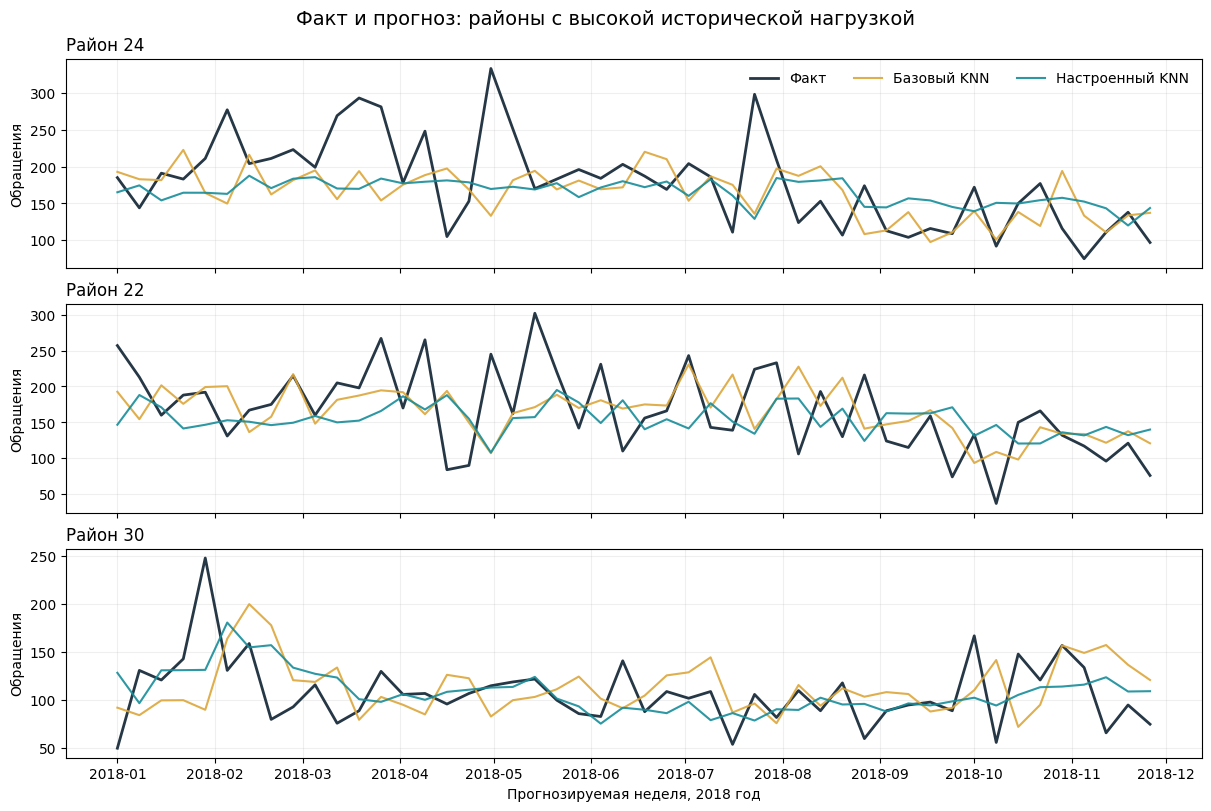

In [17]:
forecast = test_r[["area", "week", "y", "lag_1"]].copy()
forecast["Базовый KNN"] = reg_predictions["sklearn, базовый"]
forecast["Настроенный KNN"] = reg_predictions["sklearn, улучшенный"]
chosen_areas = dev_r.groupby("area").y.mean().nlargest(3).index
colors = {"Факт": "#263746", "Базовый KNN": "#dda63a", "Настроенный KNN": "#168d99"}
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout="constrained")
for ax, area in zip(axes, chosen_areas):
    part = forecast[forecast.area == area].sort_values("week")
    ax.plot(part.week, part.y, color=colors["Факт"], label="Факт", linewidth=2)
    for label in ["Базовый KNN", "Настроенный KNN"]:
        ax.plot(part.week, part[label], color=colors[label], label=label, alpha=0.9)
    ax.set_title(f"Район {area}", loc="left")
    ax.set_ylabel("Обращения")
    ax.grid(alpha=0.2)
axes[0].legend(ncol=3, frameon=False)
axes[-1].set_xlabel("Прогнозируемая неделя, 2018 год")
fig.suptitle("Факт и прогноз: районы с высокой исторической нагрузкой", fontsize=14)
plt.show()

Линии позволяют увидеть, насколько модель следует за изменением нагрузки и сглаживает отдельные всплески. Эти три района служат примерами; качество по всем 77 районам оценим на следующем рисунке.

### 5.4. Ошибки прогноза

Покажем фактические и предсказанные значения, распределение остатков, городскую сумму и районы с наибольшей MAE настроенного KNN. Остаток определим как факт минус прогноз: положительное значение означает недооценку нагрузки. Для городской суммы ошибки разных районов могут компенсироваться, поэтому её нельзя подменять основной районной метрикой.

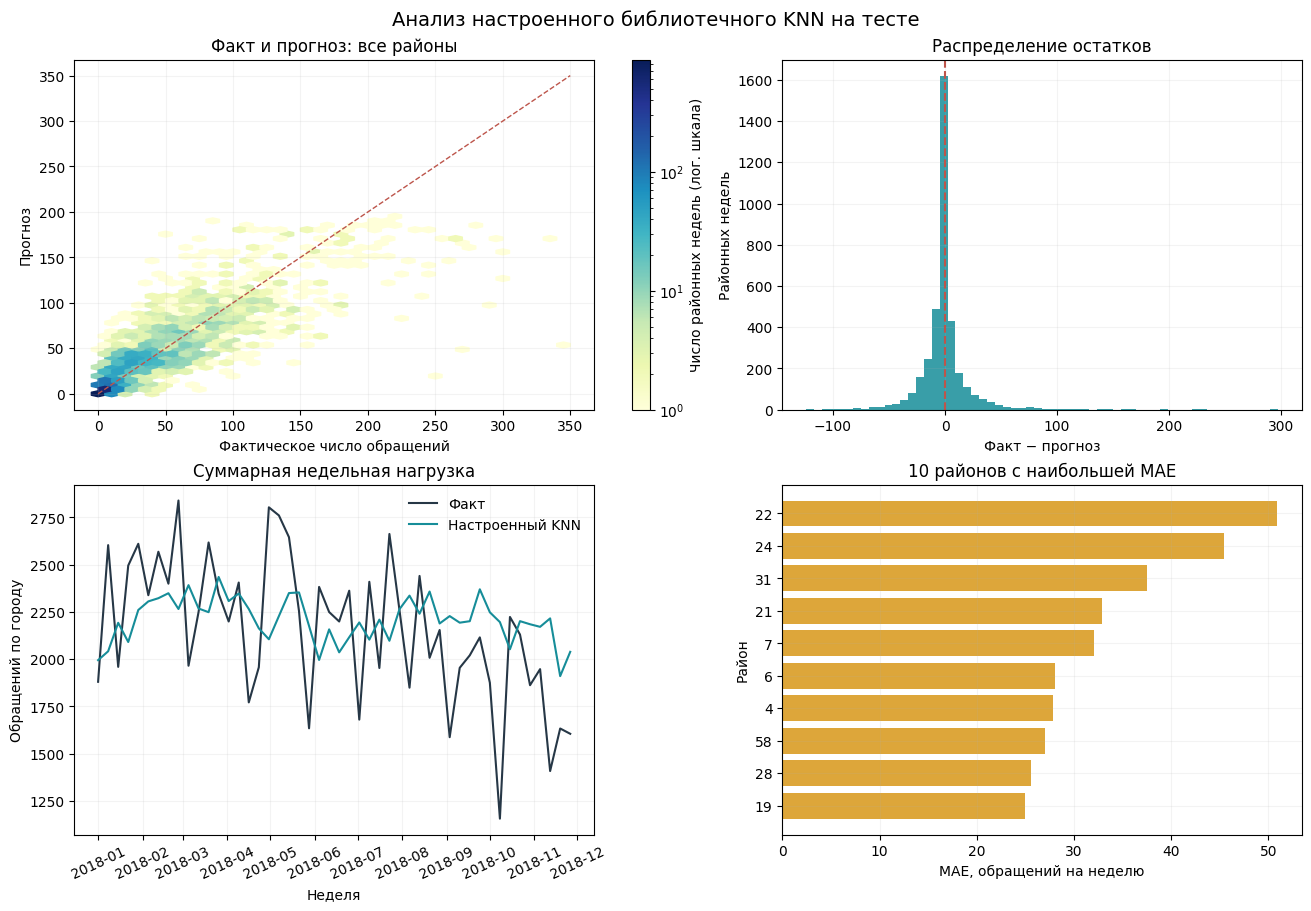

Средний остаток: -0.69
90-й процентиль абсолютной ошибки: 29.4


In [18]:
forecast["Остаток"] = forecast.y - forecast["Настроенный KNN"]
forecast["Абсолютная ошибка"] = forecast["Остаток"].abs()
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
ax = axes[0, 0]
density = ax.hexbin(forecast.y, forecast["Настроенный KNN"], gridsize=35, mincnt=1,
                    cmap="YlGnBu", bins="log")
limit = max(forecast.y.max(), forecast["Настроенный KNN"].max())
ax.plot([0, limit], [0, limit], "--", color="#bd554b", linewidth=1)
ax.set(xlabel="Фактическое число обращений", ylabel="Прогноз", title="Факт и прогноз: все районы")
fig.colorbar(density, ax=ax, label="Число районных недель (лог. шкала)")
ax = axes[0, 1]
ax.hist(forecast["Остаток"], bins=60, color="#168d99", alpha=0.85)
ax.axvline(0, color="#bd554b", linestyle="--")
ax.set(xlabel="Факт − прогноз", ylabel="Районных недель", title="Распределение остатков")
ax = axes[1, 0]
totals = forecast.groupby("week")[["y", "Базовый KNN", "Настроенный KNN"]].sum()
ax.plot(totals.index, totals.y, label="Факт", color=colors["Факт"])
ax.plot(totals.index, totals["Настроенный KNN"], label="Настроенный KNN", color=colors["Настроенный KNN"])
ax.set(xlabel="Неделя", ylabel="Обращений по городу", title="Суммарная недельная нагрузка")
ax.legend(frameon=False)
ax.tick_params(axis="x", rotation=25)
ax = axes[1, 1]
area_errors = forecast.groupby("area")["Абсолютная ошибка"].mean().nlargest(10).sort_values()
ax.barh(area_errors.index.astype(str), area_errors.values, color="#dda63a")
ax.set(xlabel="MAE, обращений на неделю", ylabel="Район", title="10 районов с наибольшей MAE")
for ax in axes.flat:
    ax.grid(alpha=0.15)
fig.suptitle("Анализ настроенного библиотечного KNN на тесте", fontsize=14)
plt.show()
print("Средний остаток:", round(forecast["Остаток"].mean(), 2))
print("90-й процентиль абсолютной ошибки:", round(forecast["Абсолютная ошибка"].quantile(0.9), 2))

Диагональ на первом графике соответствует точному прогнозу. При высоких фактических значениях заметны точки ниже диагонали: модель сглаживает сильные всплески нагрузки. Длинный правый хвост остатков также показывает крупные недооценки и помогает объяснить разницу между MAE и RMSE. Городской прогноз заметно более плавный, чем фактическая недельная сумма; в конце тестового периода встречается её переоценка. Районы с большой абсолютной MAE могут одновременно иметь высокую нагрузку: по этому графику нельзя заключить, что относительное качество там хуже. Все эти графики используются для анализа уже выбранной модели; повторного подбора по тесту не выполняем.

## 6. Сохранение результатов

Сохраним восемь тестовых оценок в `results/lab01_knn.json`, параметры и предобработку, таблицы экспериментов CV, средние метрики и разброс по фолдам. Добавим контрольные суммы данных и состава каждой части, чтобы при общем сравнении проверять одинаковые условия.

In [19]:
import hashlib
import json
import platform
import sklearn

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def split_description(frame, task):
    if task == "classification":
        members = drug.loc[frame.index, "id"].astype(int).sort_values().astype(str).tolist()
    else:
        keys = frame.sort_values(["area", "week"])
        members = (keys.area.astype(str) + ":" + keys.week.dt.strftime("%Y-%m-%d")).tolist()
    return {"rows": len(frame), "members_sha256": hashlib.sha256("\n".join(members).encode("utf-8")).hexdigest()}

records = []
for task, source in [("classification", cls_results), ("regression", reg_results)]:
    for row in source:
        label = row["Вариант"]
        tuned = "улучшенный" in label
        implementation = "sklearn" if label.startswith("sklearn") else "numpy"
        if task == "classification":
            params = {"n_neighbors": int(best_c.k) if tuned else 5,
                      "weights": str(best_c.weights) if tuned else "uniform",
                      "p": int(best_c.p) if tuned else 2,
                      "threshold": float(best_c.threshold) if tuned else 0.5,
                      "metric": "manhattan" if tuned and int(best_c.p) == 1 else "euclidean"}
            features = (final_cls_preparation.numeric_ + list(final_cls_preparation.categories_)) if tuned else feature_columns
            preparation = {"representation": str(best_c.representation) if tuned else "numeric",
                           "standard_scaler": bool(best_c.scaled) if tuned else False,
                           "categorical_features": list(final_cls_preparation.categories_) if tuned else [],
                           "unknown_category": "all zeros", "area_encoding": None}
        else:
            params = {"n_neighbors": int(best_r.k) if tuned else 5,
                      "weights": str(best_r.weights) if tuned else "uniform", "metric": "euclidean"}
            features = ["area"] + (improved_cols if tuned else base_cols[1:])
            preparation = {"standard_scaler": tuned, "area_encoding": "one_hot" if tuned else "numeric_code"}
        records.append({"task": task, "algorithm": "knn", "implementation": implementation,
                        "variant": "tuned" if tuned else "baseline", "evaluation_split": "test",
                        "metrics": {name: float(value) for name, value in row.items() if name != "Вариант"},
                        "parameters": params, "input_features": list(features), "preprocessing": preparation,
                        "cv_metrics": cv_record_metrics[(task, implementation, "tuned" if tuned else "baseline")]})

results_payload = {
    "schema_version": 2,
    "lab": 1,
    "algorithm": "knn",
    "environment": {"python": platform.python_version(), "numpy": np.__version__,
                    "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "datasets": {
        "classification": {"name": "Drug Consumption (Quantified)", "sha256": file_sha256(DRUG_PATH),
                           "target": "cannabis CL3-CL6 = 1; CL0-CL2 = 0", "random_state": RANDOM_STATE},
        "regression": {"name": "Chicago Graffiti Removal Historical", "sha256": file_sha256(GRAFFITI_PATH),
                       "target": "new requests per Community Area and target week",
                       "protocol": "weekly one-step forecast; duplicates excluded; actual past weeks available",
                       "development_end_exclusive": "2018-01-01",
                       "test_end_exclusive": "2018-12-01"},
    },
    "splits": {
        "classification": {name: split_description(frame, "classification") for name, frame in
                           [("development", X_dev_c), ("test", X_test_c)]},
        "regression": {name: split_description(frame, "regression") for name, frame in
                       [("development", dev_r), ("test", test_r)]},
    },
    "cross_validation": {
        "classification_method": "StratifiedKFold(n_splits=3, shuffle=True, random_state=42)",
        "regression_method": "expanding window; validation years 2015, 2016, 2017",
        "standard_deviation": "sample std across 3 folds, ddof=1; not a confidence interval",
        "classification_folds": [{"fold": i, "train": split_description(X_dev_c.iloc[tr], "classification"),
                                  "validation": split_description(X_dev_c.iloc[va], "classification")}
                                 for i, (tr, va) in enumerate(cls_folds, 1)],
        "regression_folds": [{"fold": i, "train": split_description(dev_r.iloc[tr], "regression"),
                              "validation": split_description(dev_r.iloc[va], "regression"),
                              "validation_year": int(dev_r.iloc[va].week.dt.year.iloc[0])}
                             for i, (tr, va) in enumerate(reg_folds, 1)],
        "selected_models": [{k: v for k, v in row.items() if pd.notna(v)} for row in cv_comparison.to_dict(orient="records")],
    },
    "validation": {"classification_search": cls_search.to_dict(orient="records"),
                   "classification_threshold_search": threshold_search.to_dict(orient="records"),
                   "regression_preparation": reg_hypotheses.to_dict(orient="records"),
                   "regression_search": reg_search.to_dict(orient="records")},
    "reference_test": {"regression_previous_week_MAE": float(mean_absolute_error(test_r.y, test_r.lag_1))},
    "results": records,
}
assert len(records) == 8
assert len({(r["task"], r["implementation"], r["variant"]) for r in records}) == 8
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
result_path = RESULTS_DIR / "lab01_knn.json"
result_path.write_text(json.dumps(results_payload, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Результаты сохранены:", result_path)
print("Записей:", len(records))

Результаты сохранены: results\lab01_knn.json
Записей: 8


## 7. Выводы

В работе сравнили KNN из sklearn и собственную реализацию для классификации и регрессии. Признаки и параметры проверяли на трёх общих фолдах, преобразования обучали только на обучающей части каждого фолда. Тесты и цели сохранили одинаковыми с другими лабораторными.

Для классификации исследовали выбор расстояния, категориальное кодирование демографии, личностные шкалы, параметры соседей и порог положительного ответа. Выбран вариант «все числовые признаки» с числом соседей 21, p=2, весами `uniform` и порогом 0.50. Средний F1 на CV составил 0.8200 против 0.7982 у исходного. На тесте получили 0.8163 против 0.8229. Таблицы показывают как подтвердившиеся гипотезы, так и варианты, не улучшившие среднюю оценку.

В регрессии выбранный вариант использует историю обращений, сезонность, стандартизацию и one-hot района. Его средний MAE на временной CV равен 10.97, на тесте — 11.44 против 11.83 у исходного KNN. Модель сглаживает отдельные всплески нагрузки, поэтому MAE рассматриваем вместе с RMSE и графиками остатков.

Собственная реализация поддерживает оба проверенных расстояния и оба способа взвешивания. Её прогнозы проверили на искусственных данных и сопоставили с библиотечными на CV и тесте. Восемь тестовых оценок, параметры, таблицы поиска и контрольные суммы разбиений сохранены в JSON. Расширенный поиск на тех же фолдах остаётся исследовательским: разброс трёх фолдов не доказывает статистическую значимость и не заменяет независимой проверки.